# G1 RSS output — publication timeline

Using data file: /home/user/g1/g1_articles.jsonl
Articles per day:
published_dt
2016-01-06      1
2016-01-11      1
2016-01-20      1
2016-02-01      1
2016-02-02      1
2016-02-03      1
2016-02-23      1
2016-02-25      1
2016-02-29      1
2016-03-04      1
2016-03-08      1
2016-03-09      1
2016-03-10      3
2016-03-11      1
2016-03-22      1
2016-05-04      1
2016-05-05      2
2016-05-06      2
2016-05-08      2
2016-05-09      1
2016-05-10      1
2016-05-11      2
2016-05-12      1
2016-05-13      1
2016-05-16      1
2016-05-20      2
2016-05-21      1
2016-05-24      1
2016-05-25      3
2016-05-30      1
2016-05-31      2
2016-06-01      2
2016-06-02      2
2016-06-03      1
2016-06-04      3
2016-06-05      1
2016-06-06      1
2016-06-07      2
2016-06-08      2
2016-06-09      1
2016-06-10      2
2016-06-13      3
2016-06-14      1
2016-06-18      1
2016-06-25      1
2016-06-26      1
2016-06-27      1
2016-06-28      1
2016-06-29      2
2016-06-30      1
2016-07-11      1
20

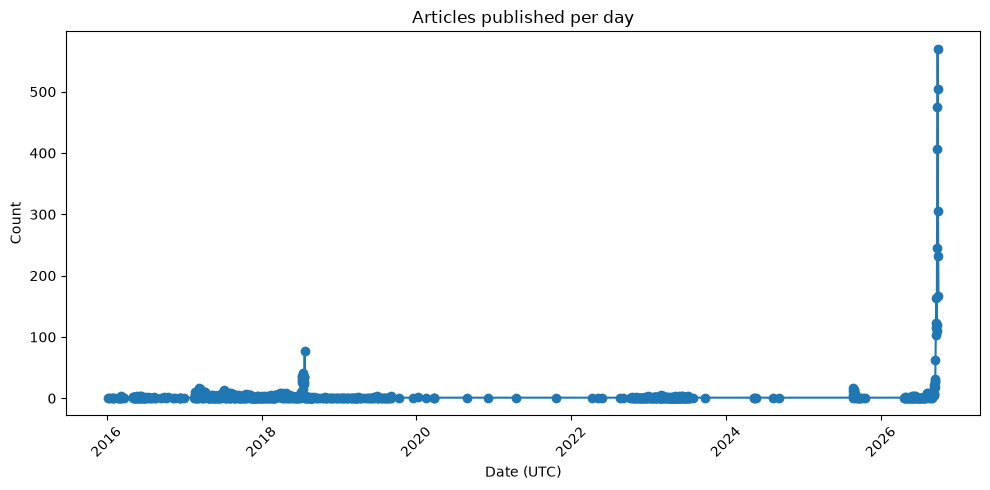

In [1]:

from pathlib import Path
import json

def find_data_file():
    candidates = [Path("g1_articles.jsonl"), Path("../g1_articles.jsonl"), Path("../../g1_articles.jsonl")]
    for c in candidates:
        if c.exists():
            return c
    for p in Path.cwd().rglob("g1_articles.jsonl"):
        return p
    raise FileNotFoundError("g1_articles.jsonl not found")

DATA_FILE = find_data_file()
print("Using data file:", DATA_FILE.resolve())

import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
rows = [json.loads(line) for line in DATA_FILE.read_text(encoding="utf-8").splitlines() if line.strip()]
df = pd.DataFrame(rows)
df["published_dt"] = pd.to_datetime(df["published"], errors="coerce", utc=True)
daily = df.dropna(subset=["published_dt"]).groupby(df["published_dt"].dt.date).size()
print("Articles per day:")
print(daily.to_string())
fig, ax = plt.subplots(figsize=(10, 5))
daily.plot(ax=ax, marker="o")
ax.set_title("Articles published per day")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()


Using data file: /home/user/g1/g1_articles.jsonl


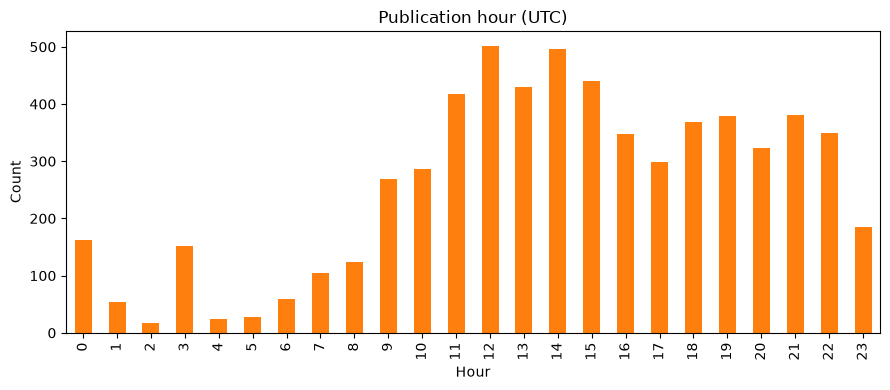

In [2]:

from pathlib import Path
import json

def find_data_file():
    candidates = [Path("g1_articles.jsonl"), Path("../g1_articles.jsonl"), Path("../../g1_articles.jsonl")]
    for c in candidates:
        if c.exists():
            return c
    for p in Path.cwd().rglob("g1_articles.jsonl"):
        return p
    raise FileNotFoundError("g1_articles.jsonl not found")

DATA_FILE = find_data_file()
print("Using data file:", DATA_FILE.resolve())

import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
rows = [json.loads(line) for line in DATA_FILE.read_text(encoding="utf-8").splitlines() if line.strip()]
df = pd.DataFrame(rows)
df["published_dt"] = pd.to_datetime(df["published"], errors="coerce", utc=True)
hours = df["published_dt"].dt.hour.dropna().astype(int)
fig, ax = plt.subplots(figsize=(9, 4))
hours.value_counts().sort_index().plot(kind="bar", ax=ax, color="#ff7f0e")
ax.set_title("Publication hour (UTC)")
ax.set_xlabel("Hour")
ax.set_ylabel("Count")
plt.tight_layout()
